### Experiment NO : 05

#### Support Vector Machine

#### Import Libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report



#### Load Dataset

In [7]:
df = pd.read_csv('Social_Network_Ads.csv')
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [8]:
df.shape

(400, 5)

#### Scale Feature

In [9]:

X = df.iloc[:, [2, 3]]  # Age and Estimated Salary
Y = df.iloc[:, 4]       # Purchased

X_Train, X_Test, Y_Train, Y_Test = train_test_split(
    X, Y, test_size=0.25, random_state=0
)

print("Training data:", X_Train.shape)
print("Testing data:", X_Test.shape)

Training data: (300, 2)
Testing data: (100, 2)


#### Feature Scaling

In [10]:
sc_X = StandardScaler()

X_Train = sc_X.fit_transform(X_Train)
X_Test = sc_X.transform(X_Test)

#### Rbf kernel

In [11]:
classifier = SVC(kernel='rbf', random_state=0)

classifier.fit(X_Train, Y_Train)

Y_Pred = classifier.predict(X_Test)

print("RBF Kernel Accuracy:",
      metrics.accuracy_score(Y_Test, Y_Pred))

RBF Kernel Accuracy: 0.93


#### Evaluate The Model

In [12]:
print("Confusion Matrix:")
print(confusion_matrix(Y_Test, Y_Pred))

print("\nClassification Report:")
print(classification_report(Y_Test, Y_Pred))

Confusion Matrix:
[[64  4]
 [ 3 29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95        68
           1       0.88      0.91      0.89        32

    accuracy                           0.93       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.93      0.93      0.93       100



#### Visualize The decision Boundary

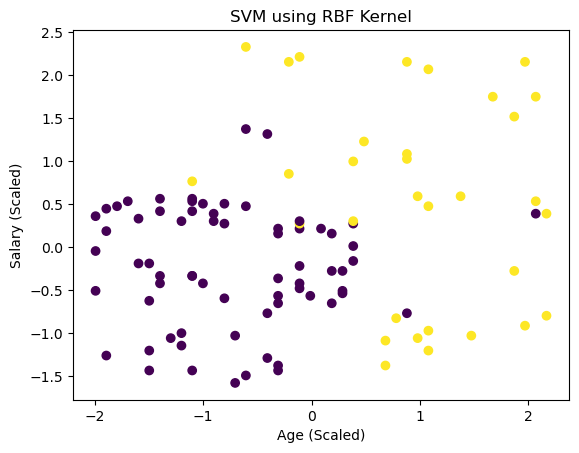

In [14]:
plt.scatter(X_Test[:, 0], X_Test[:, 1], c=Y_Test)
plt.title("SVM using RBF Kernel")
plt.xlabel("Age (Scaled)")
plt.ylabel("Salary (Scaled)")
plt.show()